In [1]:
import pandas as pd
import os

from core.visualization.kaplan_meier import plot_kaplan_meier_curves
from core.utils import load_predictions

# **Load data**

In [18]:
USE_DUMMY_DATA = False  # set True to use synthetic data (no real patient files needed)

# BONE MARROW:
SURVIVAL_DATA_PATH_BM = "data/aml_mut_pred_survival_data_bm_30-01-2026.xlsx"
MODEL_PREDICTIONS_PATH_BM = "results/6_best_aml_mutations_BM_2026-02-05_Immature granulopoietic cells"

# PERIPHERAL BLOOD:
SURVIVAL_DATA_PATH_PB = "data/aml_mut_pred_survival_data_pb_30-01-2026.xlsx"
MODEL_PREDICTIONS_PATH_PB = "results/6_best_aml_mutations_PB_2026-02-05_Monocytopoietic cells"

if USE_DUMMY_DATA:
    SURVIVAL_DATA_PATH_BM = "data/dummy/survival_data_bm.xlsx"
    SURVIVAL_DATA_PATH_PB = "data/dummy/survival_data_pb.xlsx"
    MODEL_PREDICTIONS_PATH_BM = "data/scemila_fusion_v15_predictions.csv"
    MODEL_PREDICTIONS_PATH_PB = "data/scemila_fusion_v15_predictions.csv"


### Bone marrow

In [19]:
df_survival_bm = pd.read_excel(SURVIVAL_DATA_PATH_BM)

### Peripheral blood

In [20]:
df_survival_pb = pd.read_excel(SURVIVAL_DATA_PATH_PB)

# **Overall survival**

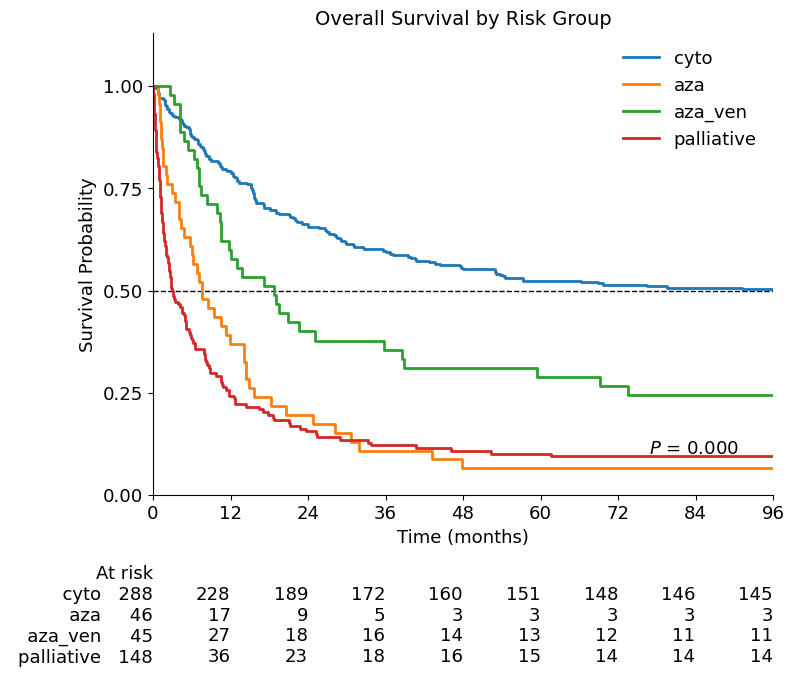

In [ ]:
# we can use either BM or PB data because same patients
df = df_survival_bm.copy()

max_time = df["time_dg_to_death"].max()
df["time_dg_to_death"] = (
    df["time_dg_to_death"]
    .fillna(max_time) / 30
)

# treatment groups
risk_cols = ["cyto", "aza", "aza_ven", "palliative"]

plot_kaplan_meier_curves(
    df=df,
    time_col="time_dg_to_death",
    event_col="died",
    group_cols=risk_cols,
    title="Overall Survival by Risk Group",
    xlim=(0, 96),
    figsize=(8, 6),
    fontsize=14,
    xlabel="Time (months)"
)

# **Survival based on MIL predictions**

In [11]:
def _extract_variable_from_folder(folder_name: str) -> str:
    """Extract the variable portion from a folder name."""
    RUN_PREFIX = "run_"
    FOLDER_SPLIT_DELIMITER = "_"
    FOLDER_VARIABLE_SPLIT_INDEX = 3  # extract everything after this index

    if RUN_PREFIX in folder_name:
        # Extract everything after the Nth underscore
        parts = folder_name.split(FOLDER_SPLIT_DELIMITER, FOLDER_VARIABLE_SPLIT_INDEX)
        return parts[-1]
    return folder_name


def collect_performance_metrics(base_dir: str, metric: str) -> pd.DataFrame:

    def _read_metric_values(df: pd.DataFrame, metric: str) -> tuple[float, float]:
        """Extract mean and std metric values from the DataFrame."""

        FOLD_COLUMN = "fold"
        FOLD_MEAN_LABEL = "mean"
        FOLD_STD_LABEL = "std"

        mean_val = df.loc[df[FOLD_COLUMN] == FOLD_MEAN_LABEL, metric].values[0]
        std_val = df.loc[df[FOLD_COLUMN] == FOLD_STD_LABEL, metric].values[0]
        return mean_val, std_val

    RESULT_FILE_NAME = "results.xlsx"
    file_path = os.path.join(base_dir, RESULT_FILE_NAME)
    df = pd.read_excel(file_path)
    mean_val, std_val = _read_metric_values(df, metric)

    return mean_val, std_val


def split_label(text):
    """
    Split a long string into two lines near the middle.
    Returns the original string if no space is found.
    """
    if not text or " " not in text:
        return text
    
    mid = len(text) // 2
    # find nearest space to the midpoint
    left_space = text.rfind(" ", 0, mid)
    right_space = text.find(" ", mid)

    # choose the closer space
    if left_space == -1:
        split_pos = right_space
    elif right_space == -1:
        split_pos = left_space
    else:
        split_pos = left_space if (mid - left_space) < (right_space - mid) else right_space

    return text[:split_pos] + "\n" + text[split_pos+1:]


def extract_prediction_results(requested_variable, prediction_result_dir):

    for run_name in os.listdir(prediction_result_dir):
        run_dir = os.path.join(prediction_result_dir, run_name)
        variable_name = _extract_variable_from_folder(run_name)
        if variable_name == requested_variable:
            all_results = []
            for item in os.listdir(run_dir):
                sub_dir = os.path.join(run_dir, item)
                if os.path.isdir(sub_dir):
                    fold_num = int(sub_dir.split("_")[-1])
                    result_path = os.path.join(sub_dir, f"cell_attention_scores_fold={fold_num}.csv")
                    results = pd.read_csv(result_path)
                    results.drop_duplicates(subset="bag_id", inplace=True)
                    results = results[["album_id", "database_id", "true_label", "pred_label", "pred_prob"]]
                    all_results.append(results)
            df = pd.concat(all_results)

            df["true_positive"] = (df["true_label"] == 1) & (df["pred_label"] == 1)
            df["false_positive"] = (df["true_label"] == 0) & (df["pred_label"] == 1)
            df["true_negative"] = (df["true_label"] == 0) & (df["pred_label"] == 0)
            df["false_negative"] = (df["true_label"] == 1) & (df["pred_label"] == 0)
            df["pred_positive"] = df["pred_label"].astype(bool)
            df["pred_negative"] = ~df["pred_positive"]
            df["target_positive"] = df["true_label"].astype(bool)
            df["target_negative"] = ~df["target_positive"]

            return df

In [45]:
def plot_all_experiments(df_survival, prediction_results_dir, treatment_groups, pairs_to_test):

    for run_name in os.listdir(prediction_results_dir):

        run_dir = os.path.join(prediction_results_dir, run_name)
        variable_name = _extract_variable_from_folder(run_name)

        # extract prediction results
        prediction_results = extract_prediction_results(requested_variable=variable_name, prediction_result_dir=prediction_results_dir)

        # merge data
        df_variable = df_survival.merge(prediction_results, on=["album_id", "database_id"], how="inner")

        # confert time to months
        max_time = df_variable["time_dg_to_death"].max()
        df_variable["time_dg_to_death"] = (
            df_variable["time_dg_to_death"]
            .fillna(max_time) / 30
        )

        for treatment_group in treatment_groups:

            # get specific treatment group
            df = df_variable[df_variable[treatment_group] == True]

            print(f"Variable: {variable_name}, Treatment group: {treatment_group}")

            if "TARGETS" in pairs_to_test:
                print("Experiment: Targets")
                risk_cols = ["target_positive", "target_negative"]
                plot_kaplan_meier_curves(
                    df=df,
                    time_col="time_dg_to_death",
                    event_col="died",
                    group_cols=risk_cols,
                    title=variable_name,
                    xlim=(0, 96),
                    figsize=(5, 3),
                    fontsize=12,
                    xlabel="Time (months)",
                    max_p_value_to_plot=0.05
                )

            if "PREDICTED" in pairs_to_test:
                print("Experiment: Predicted")
                risk_cols = ["pred_positive", "pred_negative"]
                plot_kaplan_meier_curves(
                    df=df,
                    time_col="time_dg_to_death",
                    event_col="died",
                    group_cols=risk_cols,
                    title=variable_name,
                    xlim=(0, 96),
                    figsize=(5, 3),
                    fontsize=12,
                    xlabel="Time (months)",
                    max_p_value_to_plot=0.05
                )

            if "FP_VS_TN" in pairs_to_test:
                print("Experiment: False positive vs. True negative")
                risk_cols = ["false_positive", "true_negative"]
                df_ = df[df["true_label"] == False]
                plot_kaplan_meier_curves(
                    df=df_,
                    time_col="time_dg_to_death",
                    event_col="died",
                    group_cols=risk_cols,
                    title=variable_name,
                    xlim=(0, 96),
                    figsize=(5, 3),
                    fontsize=12,
                    xlabel="Time (months)",
                    max_p_value_to_plot=0.05
                )

            if "FN_VS_TP" in pairs_to_test:
                print("False negative vs. True positive")
                risk_cols = ["false_negative", "true_positive"]
                df_ = df[df["true_label"] == True]
                if len(df_) > 0:
                    plot_kaplan_meier_curves(
                        df=df_,
                        time_col="time_dg_to_death",
                        event_col="died",
                        group_cols=risk_cols,
                        title=variable_name,
                        xlim=(0, 96),
                        figsize=(5, 3),
                        fontsize=12,
                        xlabel="Time (months)",
                        max_p_value_to_plot=0.05
                    )

        print("------------------------------------------------------------------------------------------------------------")

In [46]:
PAIRS_TO_TEST = [
    "TARGETS", # actual labels for baseline
    #"PREDICTED", # predicted labels
    "FP_VS_TN", # targets are wild-types/normal, but some were predicted as mutated/abnormal
    #"FN_VS_TP", # targets are mutated/abnormal, but some were predicted as wild-types/normal
]
TREATMENT_GROUPS = [
    "cyto", 
    "aza", 
    "aza_ven", 
    "palliative",
]

### Bone marrow

In [48]:
df_survival_bm.head()

,cyto,aza,aza_ven,palliative,time_dg_to_death,died,album_id,database_id,henkilotunnus
0,False,False,True,False,298.0,True,300,VisionDB_2018,02139_00197762
1,False,False,False,True,561.0,True,290,VisionDB_2013,02139_00425479
2,False,False,False,True,12.0,True,306,VisionDB_2016,02139_00569925
3,False,True,False,False,470.0,True,298,VisionDB_2018,02139_00648785
4,True,False,False,False,NaN,False,1777,VisionDB_2021,02139_00818770


Variable: CEBPA, Treatment group: cyto
Experiment: Targets
Experiment: False positive vs. True negative


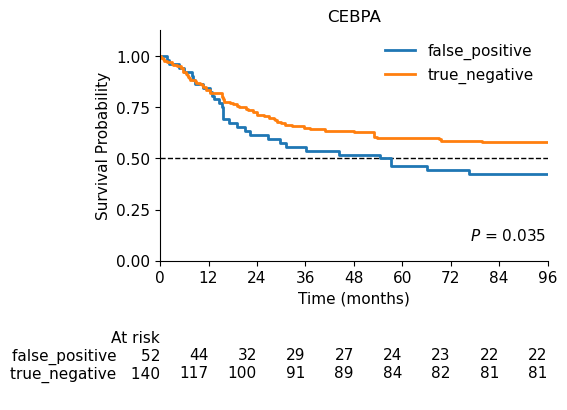

Variable: CEBPA, Treatment group: aza
Experiment: Targets
Experiment: False positive vs. True negative
Variable: CEBPA, Treatment group: aza_ven
Experiment: Targets
Experiment: False positive vs. True negative
Variable: CEBPA, Treatment group: palliative
Experiment: Targets
Experiment: False positive vs. True negative
------------------------------------------------------------------------------------------------------------
Variable: KIT, Treatment group: cyto
Experiment: Targets
Experiment: False positive vs. True negative
Variable: KIT, Treatment group: aza
Experiment: Targets


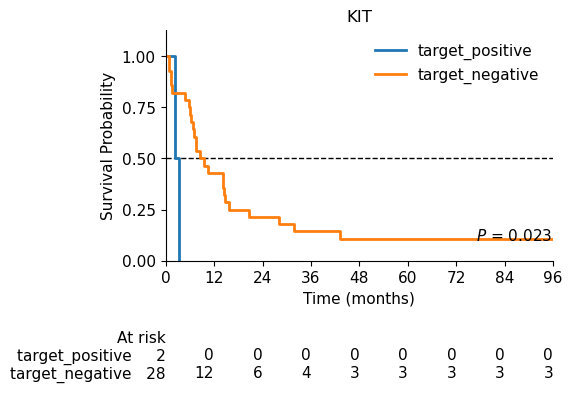

Experiment: False positive vs. True negative
Variable: KIT, Treatment group: aza_ven
Experiment: Targets
Experiment: False positive vs. True negative
Variable: KIT, Treatment group: palliative
Experiment: Targets
Experiment: False positive vs. True negative
------------------------------------------------------------------------------------------------------------
Variable: monosomy5_del_5q, Treatment group: cyto
Experiment: Targets


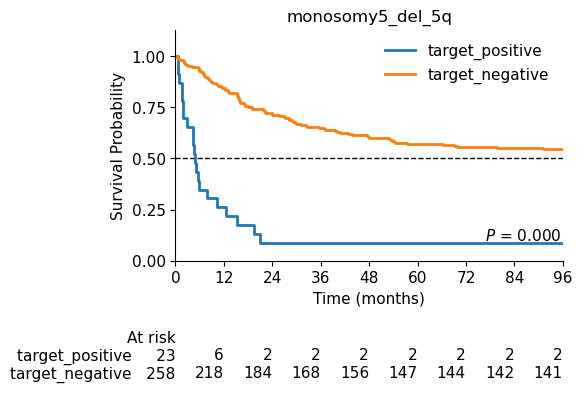

Experiment: False positive vs. True negative


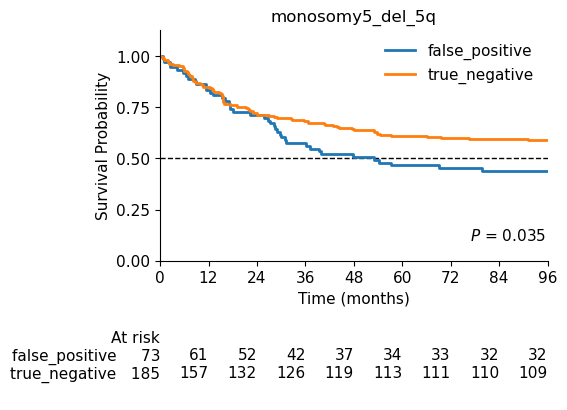

Variable: monosomy5_del_5q, Treatment group: aza
Experiment: Targets
Experiment: False positive vs. True negative
Variable: monosomy5_del_5q, Treatment group: aza_ven
Experiment: Targets
Experiment: False positive vs. True negative
Variable: monosomy5_del_5q, Treatment group: palliative
Experiment: Targets


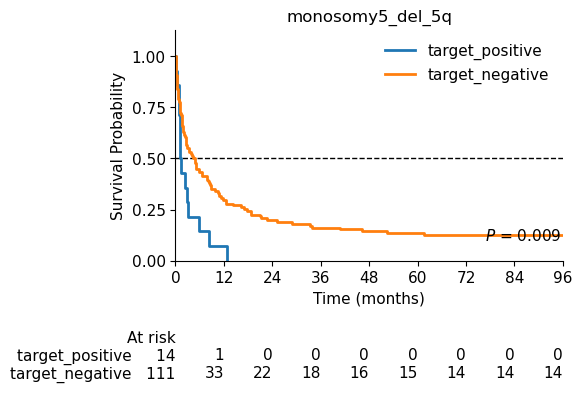

Experiment: False positive vs. True negative
------------------------------------------------------------------------------------------------------------
Variable: monosomy5, Treatment group: cyto
Experiment: Targets


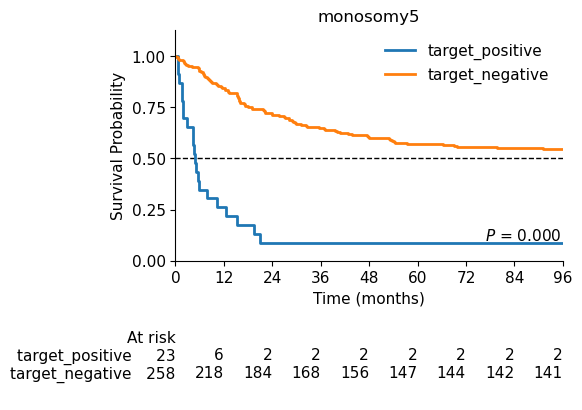

Experiment: False positive vs. True negative


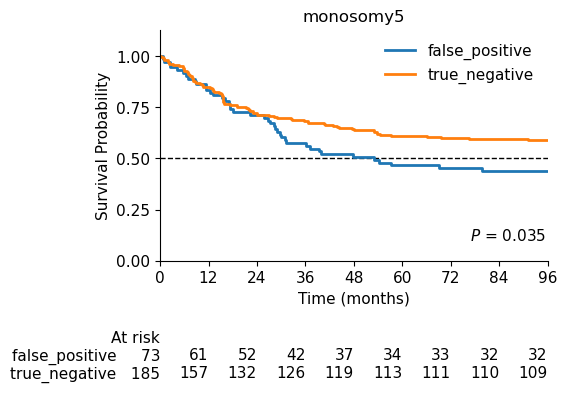

Variable: monosomy5, Treatment group: aza
Experiment: Targets
Experiment: False positive vs. True negative
Variable: monosomy5, Treatment group: aza_ven
Experiment: Targets
Experiment: False positive vs. True negative
Variable: monosomy5, Treatment group: palliative
Experiment: Targets


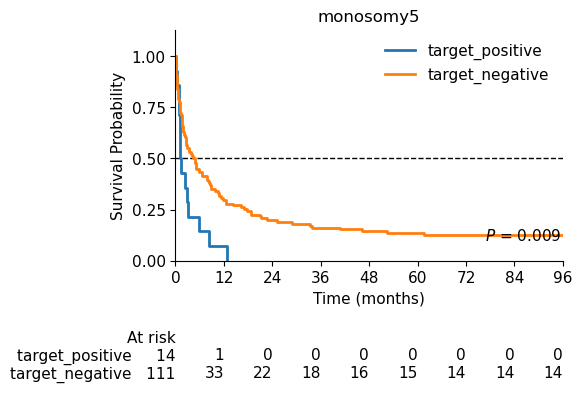

Experiment: False positive vs. True negative
------------------------------------------------------------------------------------------------------------
Variable: Spliceosome_mutations, Treatment group: cyto
Experiment: Targets
Experiment: False positive vs. True negative


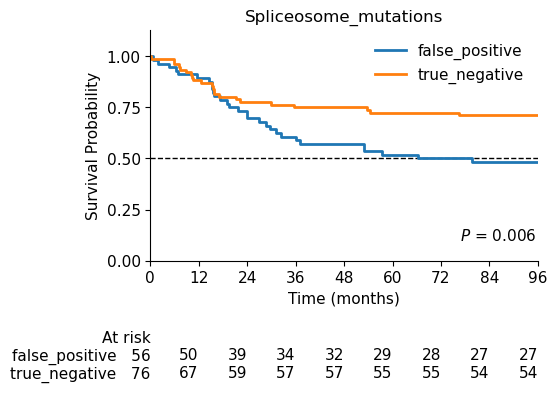

Variable: Spliceosome_mutations, Treatment group: aza
Experiment: Targets
Experiment: False positive vs. True negative


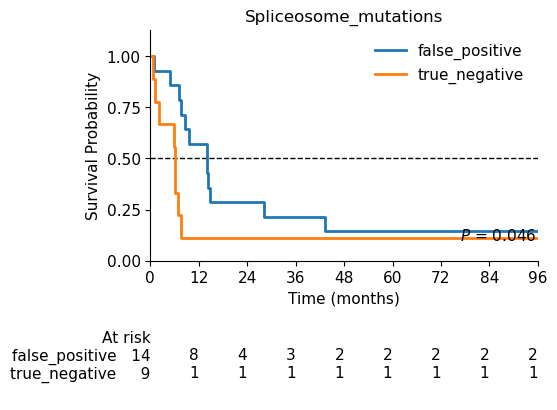

Variable: Spliceosome_mutations, Treatment group: aza_ven
Experiment: Targets
Experiment: False positive vs. True negative
Variable: Spliceosome_mutations, Treatment group: palliative
Experiment: Targets
Experiment: False positive vs. True negative
------------------------------------------------------------------------------------------------------------
Variable: RUNX1-RUNX1T1_OR_t_8_21, Treatment group: cyto
Experiment: Targets
Experiment: False positive vs. True negative
Variable: RUNX1-RUNX1T1_OR_t_8_21, Treatment group: aza
Experiment: Targets
Experiment: False positive vs. True negative
Variable: RUNX1-RUNX1T1_OR_t_8_21, Treatment group: aza_ven
Experiment: Targets
Experiment: False positive vs. True negative
Variable: RUNX1-RUNX1T1_OR_t_8_21, Treatment group: palliative
Experiment: Targets
Experiment: False positive vs. True negative
------------------------------------------------------------------------------------------------------------
Variable: IDH1, Treatment group: cyto

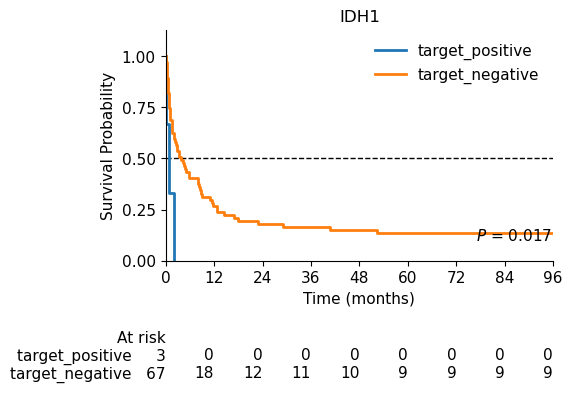

Experiment: False positive vs. True negative
------------------------------------------------------------------------------------------------------------
Variable: IDH2, Treatment group: cyto
Experiment: Targets
Experiment: False positive vs. True negative
Variable: IDH2, Treatment group: aza
Experiment: Targets
Experiment: False positive vs. True negative
Variable: IDH2, Treatment group: aza_ven
Experiment: Targets


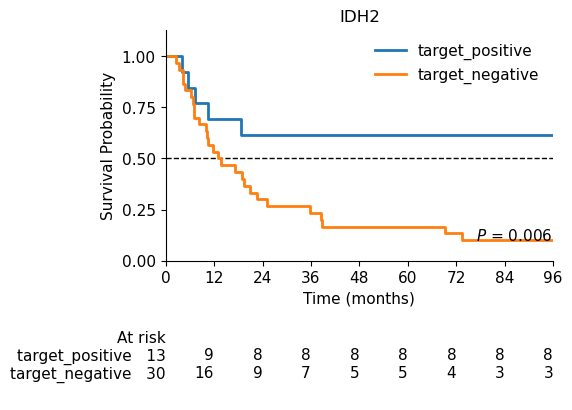

Experiment: False positive vs. True negative
Variable: IDH2, Treatment group: palliative
Experiment: Targets
Experiment: False positive vs. True negative
------------------------------------------------------------------------------------------------------------
Variable: t_11, Treatment group: cyto
Experiment: Targets


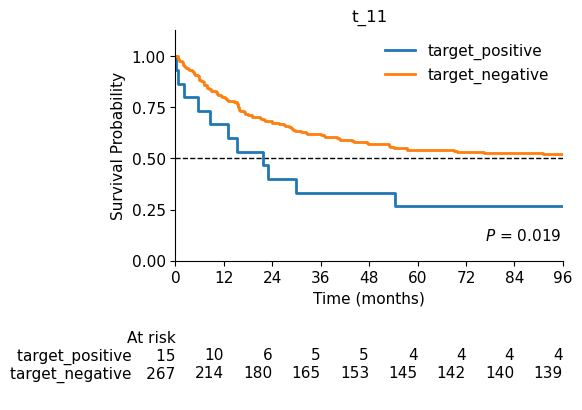

Experiment: False positive vs. True negative
Variable: t_11, Treatment group: aza
Experiment: Targets


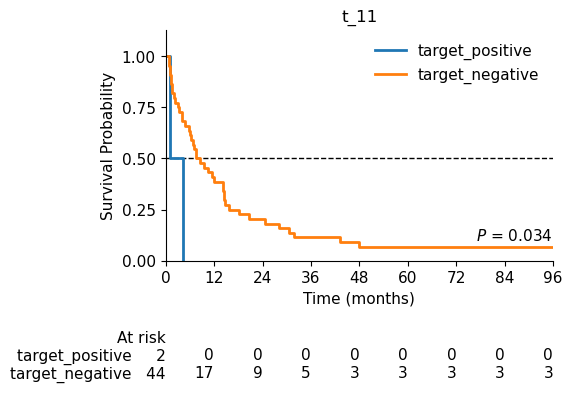

Experiment: False positive vs. True negative
Variable: t_11, Treatment group: aza_ven
Experiment: Targets
Experiment: False positive vs. True negative
Variable: t_11, Treatment group: palliative
Experiment: Targets


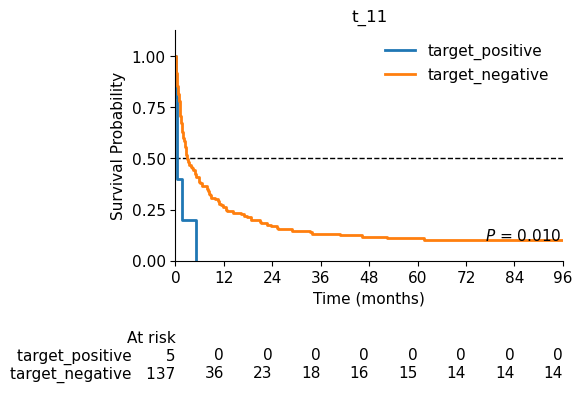

Experiment: False positive vs. True negative


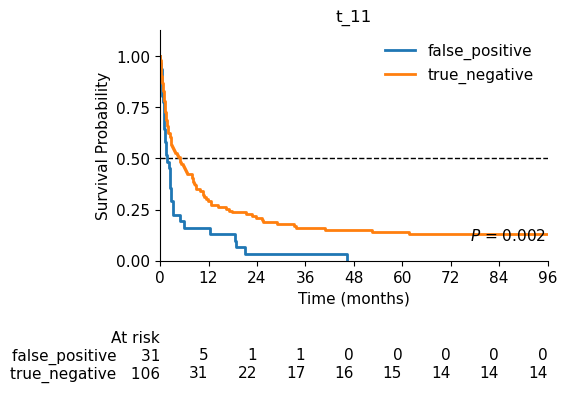

------------------------------------------------------------------------------------------------------------
Variable: TP53, Treatment group: cyto
Experiment: Targets


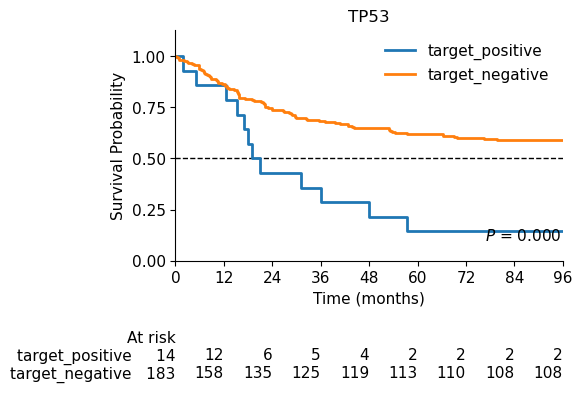

Experiment: False positive vs. True negative
Variable: TP53, Treatment group: aza
Experiment: Targets
Experiment: False positive vs. True negative
Variable: TP53, Treatment group: aza_ven
Experiment: Targets
Experiment: False positive vs. True negative
Variable: TP53, Treatment group: palliative
Experiment: Targets
Experiment: False positive vs. True negative
------------------------------------------------------------------------------------------------------------
Variable: TP53_OR_monosomy17_del_17p, Treatment group: cyto
Experiment: Targets


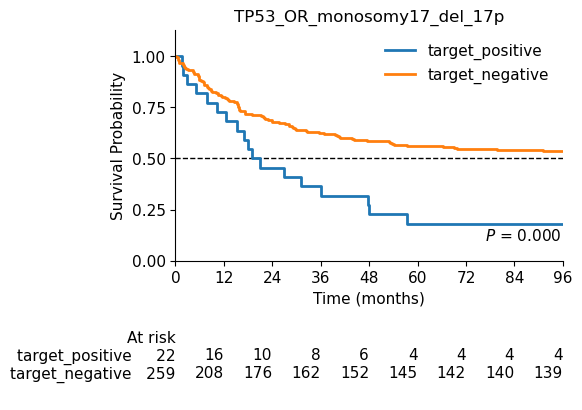

Experiment: False positive vs. True negative
Variable: TP53_OR_monosomy17_del_17p, Treatment group: aza
Experiment: Targets
Experiment: False positive vs. True negative
Variable: TP53_OR_monosomy17_del_17p, Treatment group: aza_ven
Experiment: Targets
Experiment: False positive vs. True negative
Variable: TP53_OR_monosomy17_del_17p, Treatment group: palliative
Experiment: Targets
Experiment: False positive vs. True negative
------------------------------------------------------------------------------------------------------------
Variable: MDS_related_mutations, Treatment group: cyto
Experiment: Targets


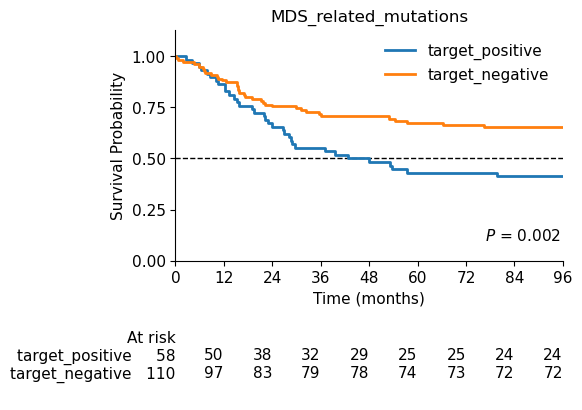

Experiment: False positive vs. True negative
Variable: MDS_related_mutations, Treatment group: aza
Experiment: Targets
Experiment: False positive vs. True negative
Variable: MDS_related_mutations, Treatment group: aza_ven
Experiment: Targets
Experiment: False positive vs. True negative
Variable: MDS_related_mutations, Treatment group: palliative
Experiment: Targets
Experiment: False positive vs. True negative
------------------------------------------------------------------------------------------------------------
Variable: IDH_mutations, Treatment group: cyto
Experiment: Targets
Experiment: False positive vs. True negative
Variable: IDH_mutations, Treatment group: aza
Experiment: Targets
Experiment: False positive vs. True negative
Variable: IDH_mutations, Treatment group: aza_ven
Experiment: Targets


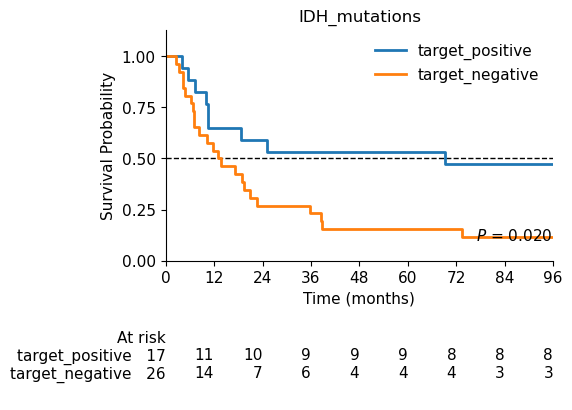

Experiment: False positive vs. True negative
Variable: IDH_mutations, Treatment group: palliative
Experiment: Targets
Experiment: False positive vs. True negative
------------------------------------------------------------------------------------------------------------
Variable: RTK_RAS_mutations, Treatment group: cyto
Experiment: Targets
Experiment: False positive vs. True negative
Variable: RTK_RAS_mutations, Treatment group: aza
Experiment: Targets
Experiment: False positive vs. True negative
Variable: RTK_RAS_mutations, Treatment group: aza_ven
Experiment: Targets
Experiment: False positive vs. True negative
Variable: RTK_RAS_mutations, Treatment group: palliative
Experiment: Targets
Experiment: False positive vs. True negative
------------------------------------------------------------------------------------------------------------
Variable: WT1, Treatment group: cyto
Experiment: Targets
Experiment: False positive vs. True negative
Variable: WT1, Treatment group: aza
Experimen

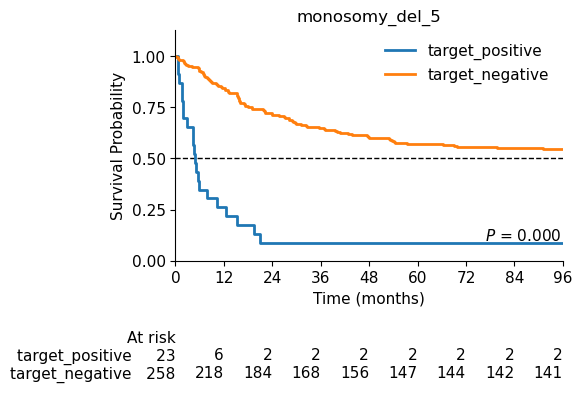

Experiment: False positive vs. True negative


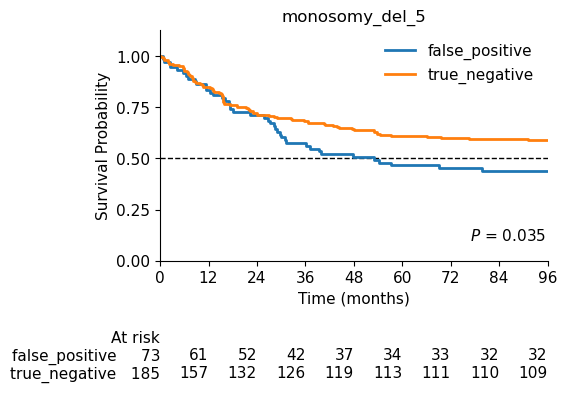

Variable: monosomy_del_5, Treatment group: aza
Experiment: Targets
Experiment: False positive vs. True negative
Variable: monosomy_del_5, Treatment group: aza_ven
Experiment: Targets
Experiment: False positive vs. True negative
Variable: monosomy_del_5, Treatment group: palliative
Experiment: Targets


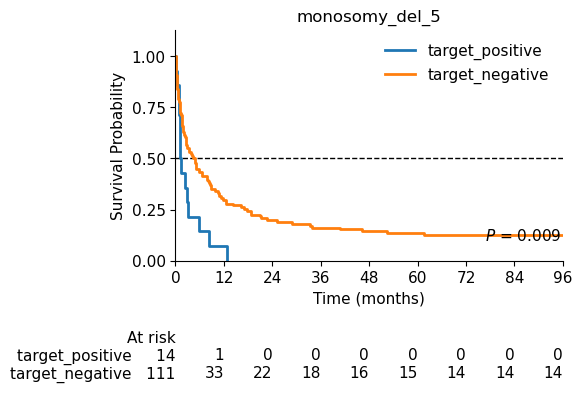

Experiment: False positive vs. True negative
------------------------------------------------------------------------------------------------------------
Variable: PML-RARA, Treatment group: cyto
Experiment: Targets
Experiment: False positive vs. True negative
Variable: PML-RARA, Treatment group: aza
Experiment: Targets
Experiment: False positive vs. True negative
Variable: PML-RARA, Treatment group: aza_ven
Experiment: Targets
Experiment: False positive vs. True negative
Variable: PML-RARA, Treatment group: palliative
Experiment: Targets


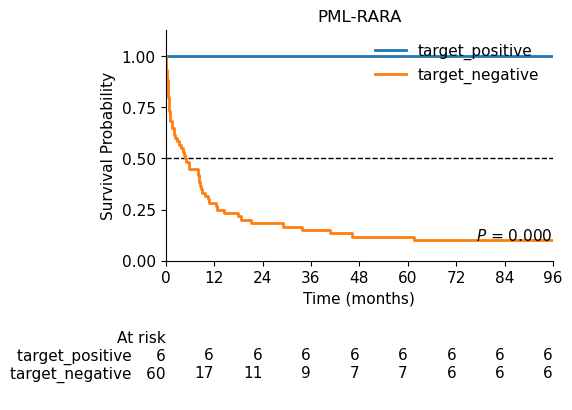

Experiment: False positive vs. True negative
------------------------------------------------------------------------------------------------------------
Variable: RUNX1, Treatment group: cyto
Experiment: Targets


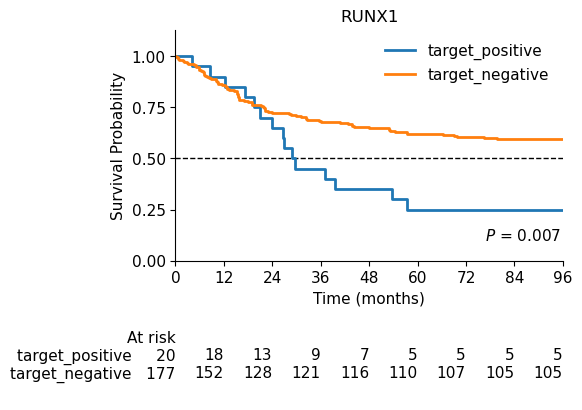

Experiment: False positive vs. True negative
Variable: RUNX1, Treatment group: aza
Experiment: Targets
Experiment: False positive vs. True negative
Variable: RUNX1, Treatment group: aza_ven
Experiment: Targets
Experiment: False positive vs. True negative
Variable: RUNX1, Treatment group: palliative
Experiment: Targets
Experiment: False positive vs. True negative
------------------------------------------------------------------------------------------------------------
Variable: STAG2, Treatment group: cyto
Experiment: Targets


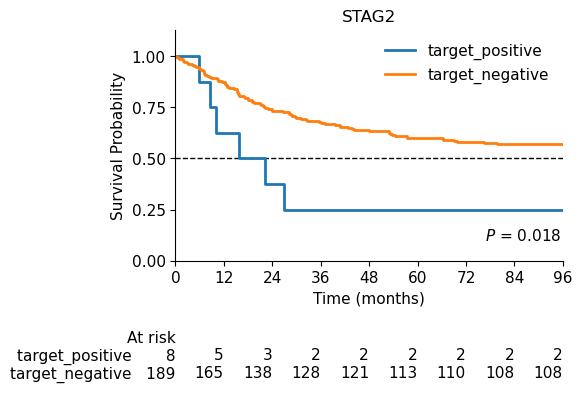

Experiment: False positive vs. True negative
Variable: STAG2, Treatment group: aza
Experiment: Targets
Experiment: False positive vs. True negative
Variable: STAG2, Treatment group: aza_ven
Experiment: Targets
Experiment: False positive vs. True negative


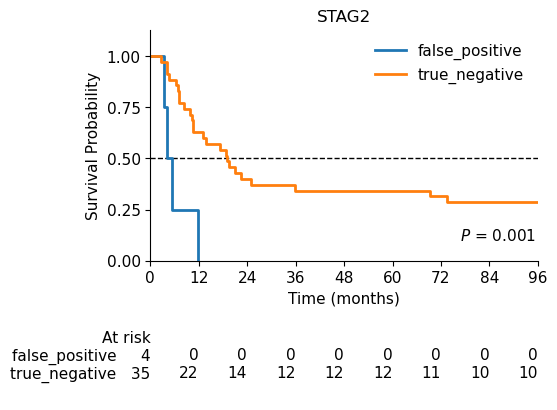

Variable: STAG2, Treatment group: palliative
Experiment: Targets
Experiment: False positive vs. True negative
------------------------------------------------------------------------------------------------------------
Variable: NRAS, Treatment group: cyto
Experiment: Targets


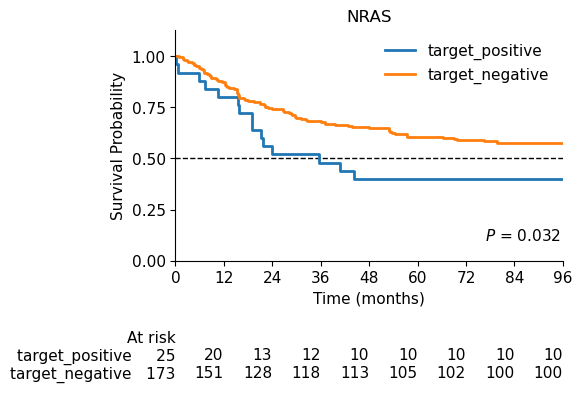

Experiment: False positive vs. True negative
Variable: NRAS, Treatment group: aza
Experiment: Targets
Experiment: False positive vs. True negative
Variable: NRAS, Treatment group: aza_ven
Experiment: Targets
Experiment: False positive vs. True negative


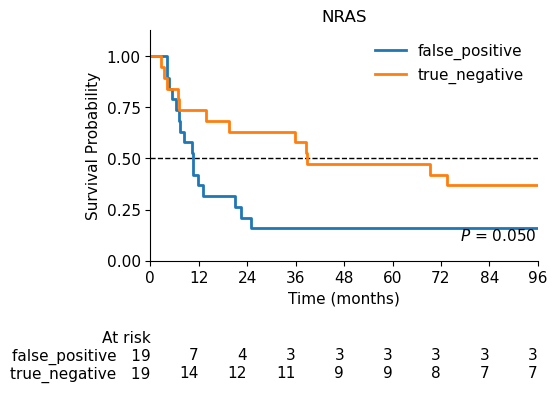

Variable: NRAS, Treatment group: palliative
Experiment: Targets
Experiment: False positive vs. True negative
------------------------------------------------------------------------------------------------------------
Variable: Transcription_mutations, Treatment group: cyto
Experiment: Targets
Experiment: False positive vs. True negative
Variable: Transcription_mutations, Treatment group: aza
Experiment: Targets
Experiment: False positive vs. True negative
Variable: Transcription_mutations, Treatment group: aza_ven
Experiment: Targets


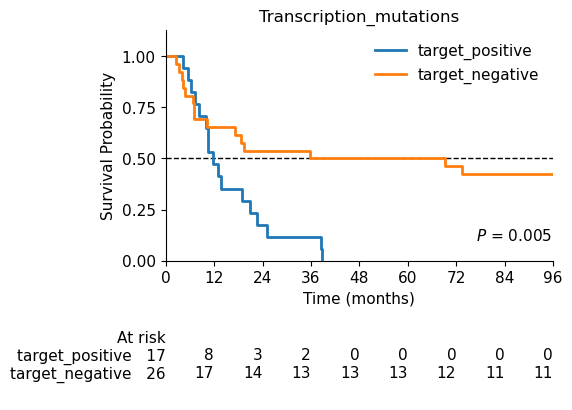

Experiment: False positive vs. True negative
Variable: Transcription_mutations, Treatment group: palliative
Experiment: Targets
Experiment: False positive vs. True negative
------------------------------------------------------------------------------------------------------------
Variable: CBFB-MYH11, Treatment group: cyto
Experiment: Targets


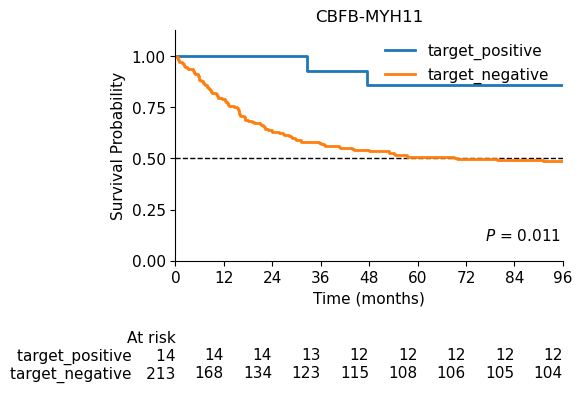

Experiment: False positive vs. True negative
Variable: CBFB-MYH11, Treatment group: aza
Experiment: Targets
Experiment: False positive vs. True negative
Variable: CBFB-MYH11, Treatment group: aza_ven
Experiment: Targets
Experiment: False positive vs. True negative
Variable: CBFB-MYH11, Treatment group: palliative
Experiment: Targets
Experiment: False positive vs. True negative
------------------------------------------------------------------------------------------------------------
Variable: NPM1, Treatment group: cyto
Experiment: Targets


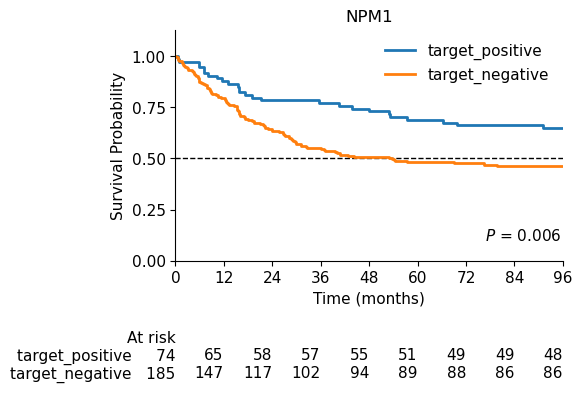

Experiment: False positive vs. True negative
Variable: NPM1, Treatment group: aza
Experiment: Targets
Experiment: False positive vs. True negative
Variable: NPM1, Treatment group: aza_ven
Experiment: Targets
Experiment: False positive vs. True negative
Variable: NPM1, Treatment group: palliative
Experiment: Targets
Experiment: False positive vs. True negative
------------------------------------------------------------------------------------------------------------
Variable: BCOR_mutations, Treatment group: cyto
Experiment: Targets


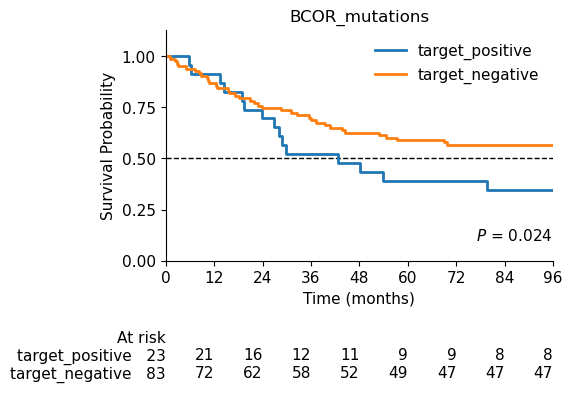

Experiment: False positive vs. True negative
Variable: BCOR_mutations, Treatment group: aza
Experiment: Targets
Experiment: False positive vs. True negative


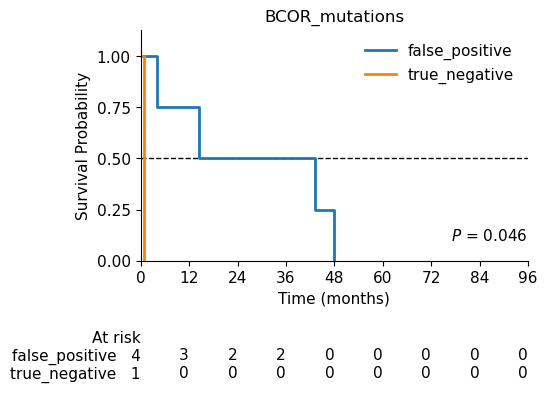

Variable: BCOR_mutations, Treatment group: aza_ven
Experiment: Targets
Experiment: False positive vs. True negative


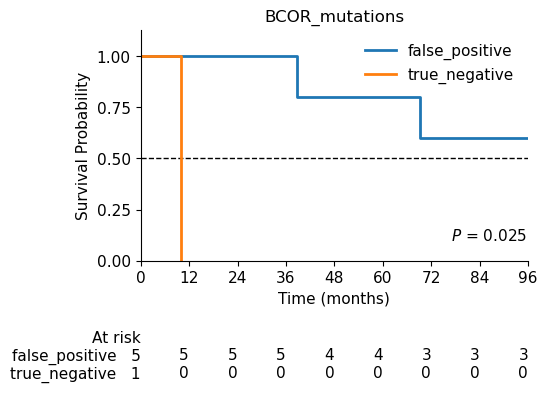

Variable: BCOR_mutations, Treatment group: palliative
Experiment: Targets
Experiment: False positive vs. True negative
------------------------------------------------------------------------------------------------------------


In [47]:
plot_all_experiments(df_survival_bm, PREDICTION_RESULTS_DIR_BM, TREATMENT_GROUPS, PAIRS_TO_TEST)

Variable: CEBPA, Treatment group: cyto


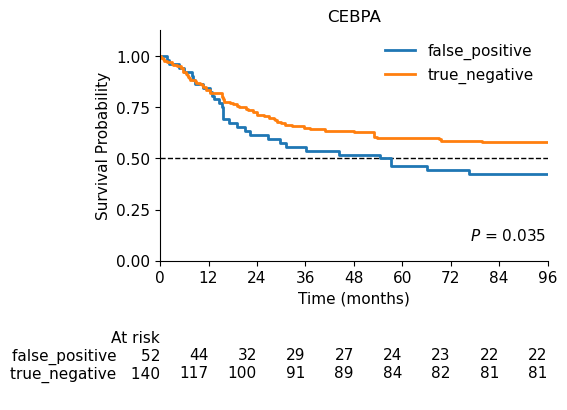

Variable: CEBPA, Treatment group: aza
Variable: CEBPA, Treatment group: aza_ven
Variable: CEBPA, Treatment group: palliative
------------------------------------------------------------------------------------------------------------
Variable: KIT, Treatment group: cyto
Variable: KIT, Treatment group: aza
Variable: KIT, Treatment group: aza_ven
Variable: KIT, Treatment group: palliative
------------------------------------------------------------------------------------------------------------
Variable: monosomy5_del_5q, Treatment group: cyto


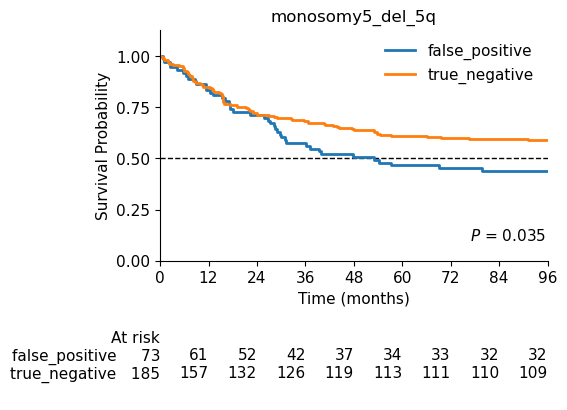

Variable: monosomy5_del_5q, Treatment group: aza
Variable: monosomy5_del_5q, Treatment group: aza_ven
Variable: monosomy5_del_5q, Treatment group: palliative
------------------------------------------------------------------------------------------------------------
Variable: monosomy5, Treatment group: cyto


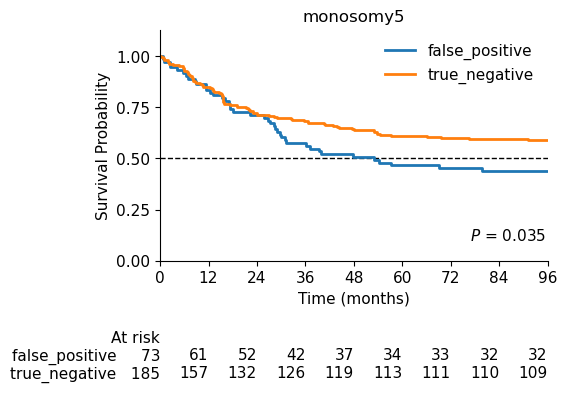

Variable: monosomy5, Treatment group: aza
Variable: monosomy5, Treatment group: aza_ven
Variable: monosomy5, Treatment group: palliative
------------------------------------------------------------------------------------------------------------
Variable: Spliceosome_mutations, Treatment group: cyto


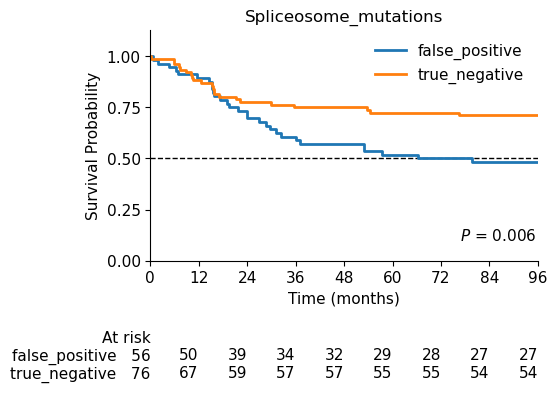

Variable: Spliceosome_mutations, Treatment group: aza


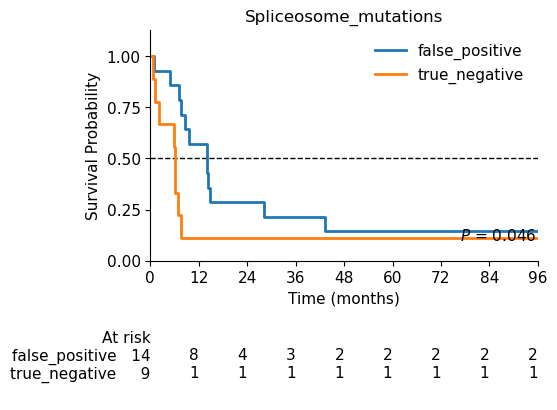

Variable: Spliceosome_mutations, Treatment group: aza_ven
Variable: Spliceosome_mutations, Treatment group: palliative
------------------------------------------------------------------------------------------------------------
Variable: RUNX1-RUNX1T1_OR_t_8_21, Treatment group: cyto
Variable: RUNX1-RUNX1T1_OR_t_8_21, Treatment group: aza
Variable: RUNX1-RUNX1T1_OR_t_8_21, Treatment group: aza_ven
Variable: RUNX1-RUNX1T1_OR_t_8_21, Treatment group: palliative
------------------------------------------------------------------------------------------------------------
Variable: IDH1, Treatment group: cyto
Variable: IDH1, Treatment group: aza
Variable: IDH1, Treatment group: aza_ven
Variable: IDH1, Treatment group: palliative
------------------------------------------------------------------------------------------------------------
Variable: IDH2, Treatment group: cyto
Variable: IDH2, Treatment group: aza
Variable: IDH2, Treatment group: aza_ven
Variable: IDH2, Treatment group: palliativ

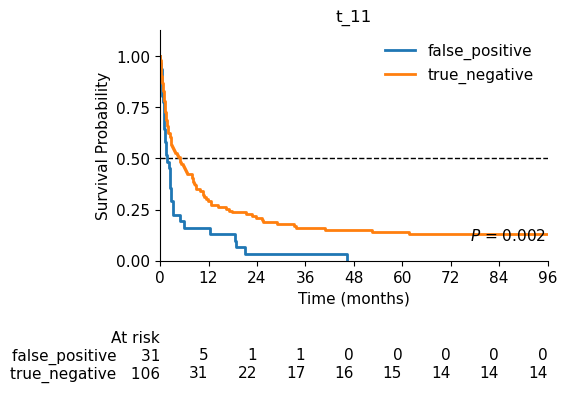

------------------------------------------------------------------------------------------------------------
Variable: TP53, Treatment group: cyto
Variable: TP53, Treatment group: aza
Variable: TP53, Treatment group: aza_ven
Variable: TP53, Treatment group: palliative
------------------------------------------------------------------------------------------------------------
Variable: TP53_OR_monosomy17_del_17p, Treatment group: cyto
Variable: TP53_OR_monosomy17_del_17p, Treatment group: aza
Variable: TP53_OR_monosomy17_del_17p, Treatment group: aza_ven
Variable: TP53_OR_monosomy17_del_17p, Treatment group: palliative
------------------------------------------------------------------------------------------------------------
Variable: MDS_related_mutations, Treatment group: cyto
Variable: MDS_related_mutations, Treatment group: aza
Variable: MDS_related_mutations, Treatment group: aza_ven
Variable: MDS_related_mutations, Treatment group: palliative
-------------------------------------

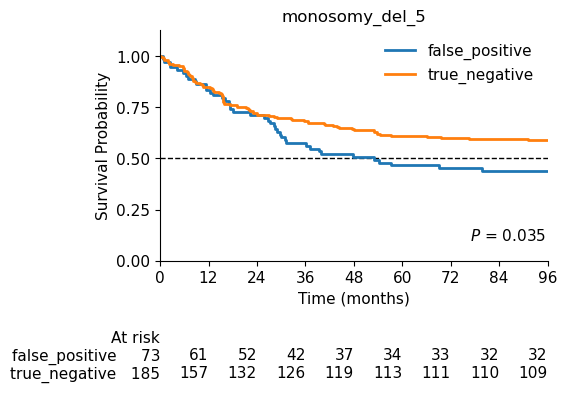

Variable: monosomy_del_5, Treatment group: aza
Variable: monosomy_del_5, Treatment group: aza_ven
Variable: monosomy_del_5, Treatment group: palliative
------------------------------------------------------------------------------------------------------------
Variable: PML-RARA, Treatment group: cyto
Variable: PML-RARA, Treatment group: aza
Variable: PML-RARA, Treatment group: aza_ven
Variable: PML-RARA, Treatment group: palliative
------------------------------------------------------------------------------------------------------------
Variable: RUNX1, Treatment group: cyto
Variable: RUNX1, Treatment group: aza
Variable: RUNX1, Treatment group: aza_ven
Variable: RUNX1, Treatment group: palliative
------------------------------------------------------------------------------------------------------------
Variable: STAG2, Treatment group: cyto
Variable: STAG2, Treatment group: aza
Variable: STAG2, Treatment group: aza_ven


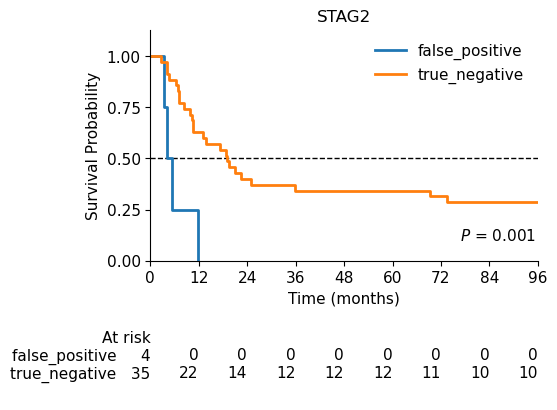

Variable: STAG2, Treatment group: palliative
------------------------------------------------------------------------------------------------------------
Variable: NRAS, Treatment group: cyto
Variable: NRAS, Treatment group: aza
Variable: NRAS, Treatment group: aza_ven


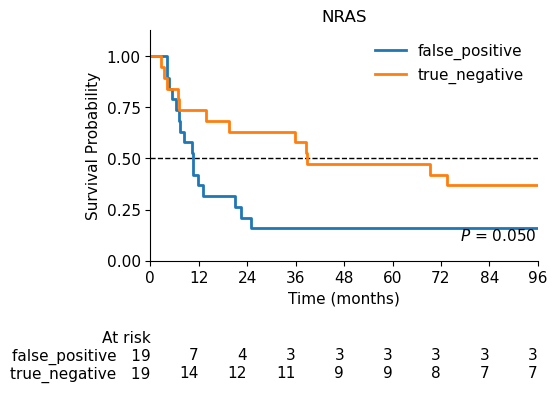

Variable: NRAS, Treatment group: palliative
------------------------------------------------------------------------------------------------------------
Variable: Transcription_mutations, Treatment group: cyto
Variable: Transcription_mutations, Treatment group: aza
Variable: Transcription_mutations, Treatment group: aza_ven
Variable: Transcription_mutations, Treatment group: palliative
------------------------------------------------------------------------------------------------------------
Variable: CBFB-MYH11, Treatment group: cyto
Variable: CBFB-MYH11, Treatment group: aza
Variable: CBFB-MYH11, Treatment group: aza_ven
Variable: CBFB-MYH11, Treatment group: palliative
------------------------------------------------------------------------------------------------------------
Variable: NPM1, Treatment group: cyto
Variable: NPM1, Treatment group: aza
Variable: NPM1, Treatment group: aza_ven
Variable: NPM1, Treatment group: palliative
-------------------------------------------------

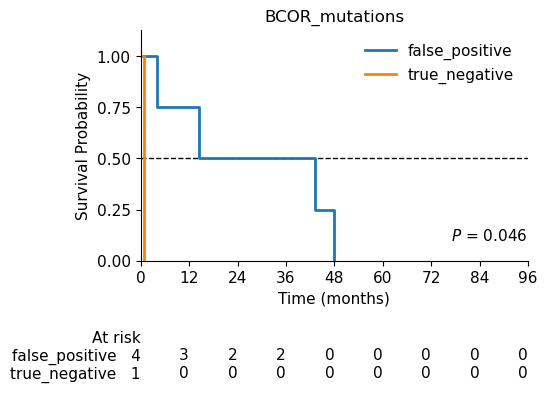

Variable: BCOR_mutations, Treatment group: aza_ven


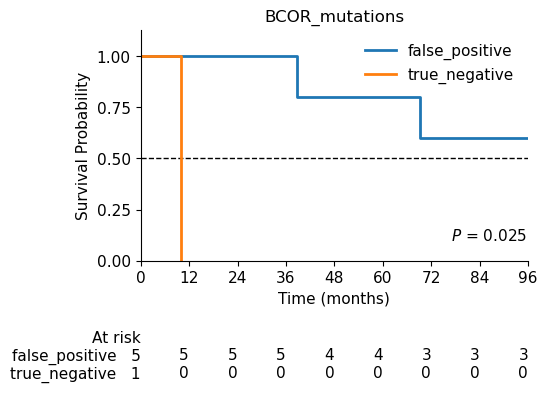

Variable: BCOR_mutations, Treatment group: palliative
------------------------------------------------------------------------------------------------------------


In [35]:
for run_name in os.listdir(PREDICTION_RESULTS_DIR_BM):

    run_dir = os.path.join(PREDICTION_RESULTS_DIR_BM, run_name)
    variable_name = _extract_variable_from_folder(run_name)

    # extract prediction results
    prediction_results = extract_prediction_results(requested_variable=variable_name, prediction_result_dir=PREDICTION_RESULTS_DIR_BM)

    # merge data
    df_variable = df_survival_bm.merge(prediction_results, on=["album_id", "database_id"], how="inner")

    # confert time to months
    max_time = df_variable["time_dg_to_death"].max()
    df_variable["time_dg_to_death"] = (
        df_variable["time_dg_to_death"]
        .fillna(max_time) / 30
    )

    for treatment_group in TREATMENT_GROUPS:

        # get specific treatment group
        df = df_variable[df_variable[treatment_group] == True]

        print(f"Variable: {variable_name}, Treatment group: {treatment_group}")

        if "TARGETS" in PAIRS_TO_TEST:
            risk_cols = ["target_positive", "target_negative"]
            plot_kaplan_meier_curves(
                df=df,
                time_col="time_dg_to_death",
                event_col="died",
                group_cols=risk_cols,
                title=variable_name,
                xlim=(0, 96),
                figsize=(5, 3),
                fontsize=12,
                xlabel="Time (months)",
                max_p_value_to_plot=0.05
            )

        if "PREDICTED" in PAIRS_TO_TEST:
            risk_cols = ["pred_positive", "pred_negative"]
            plot_kaplan_meier_curves(
                df=df,
                time_col="time_dg_to_death",
                event_col="died",
                group_cols=risk_cols,
                title=variable_name,
                xlim=(0, 96),
                figsize=(5, 3),
                fontsize=12,
                xlabel="Time (months)",
                max_p_value_to_plot=0.05
            )

        if "FP_VS_TN" in PAIRS_TO_TEST:
            risk_cols = ["false_positive", "true_negative"]
            df_ = df[df["true_label"] == False]
            plot_kaplan_meier_curves(
                df=df_,
                time_col="time_dg_to_death",
                event_col="died",
                group_cols=risk_cols,
                title=variable_name,
                xlim=(0, 96),
                figsize=(5, 3),
                fontsize=12,
                xlabel="Time (months)",
                max_p_value_to_plot=0.05
            )

        if "FN_VS_TP" in PAIRS_TO_TEST:
            risk_cols = ["false_negative", "true_positive"]
            df_ = df[df["true_label"] == True]
            if len(df_) > 0:
                plot_kaplan_meier_curves(
                    df=df_,
                    time_col="time_dg_to_death",
                    event_col="died",
                    group_cols=risk_cols,
                    title=variable_name,
                    xlim=(0, 96),
                    figsize=(5, 3),
                    fontsize=12,
                    xlabel="Time (months)",
                    max_p_value_to_plot=0.05
                )

    print("------------------------------------------------------------------------------------------------------------")

### Peripheral blood

Variable: CEBPA, Treatment group: cyto
Variable: CEBPA, Treatment group: aza
Variable: CEBPA, Treatment group: aza_ven
Variable: CEBPA, Treatment group: palliative
------------------------------------------------------------------------------------------------------------
Variable: KIT, Treatment group: cyto
Variable: KIT, Treatment group: aza


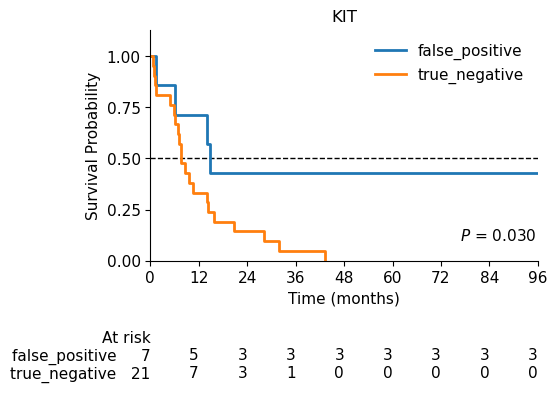

Variable: KIT, Treatment group: aza_ven
Variable: KIT, Treatment group: palliative


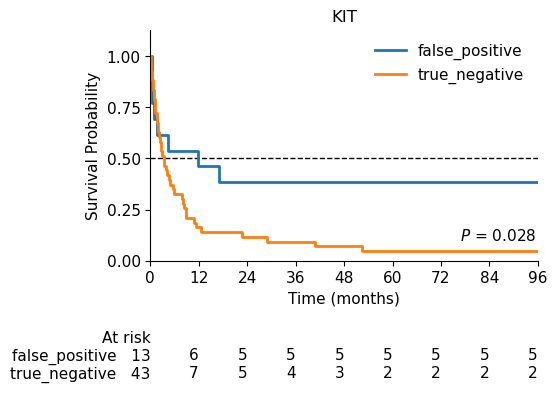

------------------------------------------------------------------------------------------------------------
Variable: monosomy5_del_5q, Treatment group: cyto


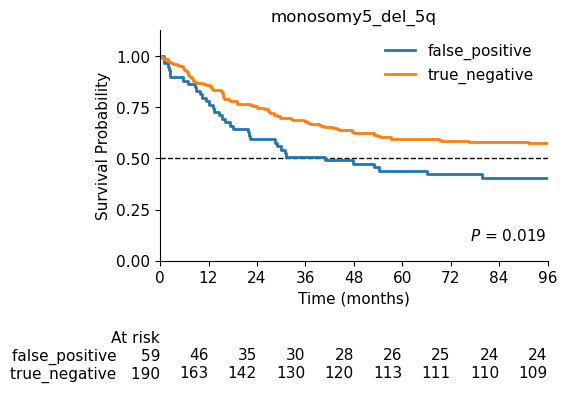

Variable: monosomy5_del_5q, Treatment group: aza
Variable: monosomy5_del_5q, Treatment group: aza_ven
Variable: monosomy5_del_5q, Treatment group: palliative


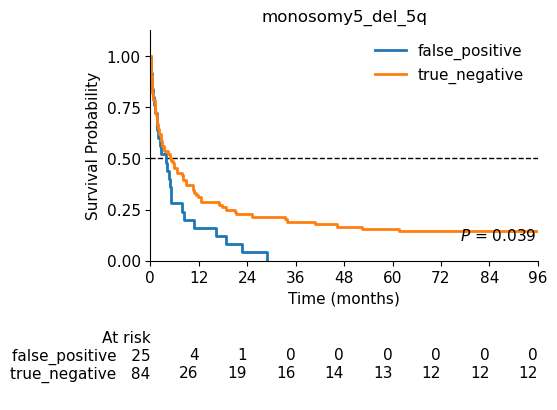

------------------------------------------------------------------------------------------------------------
Variable: monosomy5, Treatment group: cyto


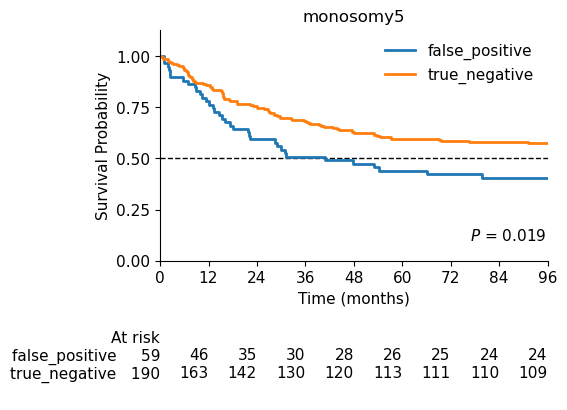

Variable: monosomy5, Treatment group: aza
Variable: monosomy5, Treatment group: aza_ven
Variable: monosomy5, Treatment group: palliative
------------------------------------------------------------------------------------------------------------
Variable: Spliceosome_mutations, Treatment group: cyto
Variable: Spliceosome_mutations, Treatment group: aza
Variable: Spliceosome_mutations, Treatment group: aza_ven
Variable: Spliceosome_mutations, Treatment group: palliative
------------------------------------------------------------------------------------------------------------
Variable: RUNX1-RUNX1T1_OR_t_8_21, Treatment group: cyto


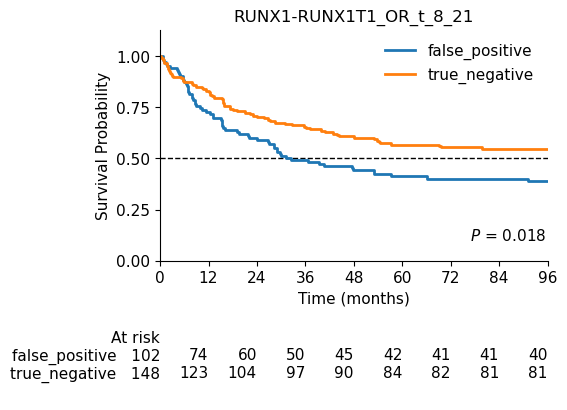

Variable: RUNX1-RUNX1T1_OR_t_8_21, Treatment group: aza
Variable: RUNX1-RUNX1T1_OR_t_8_21, Treatment group: aza_ven
Variable: RUNX1-RUNX1T1_OR_t_8_21, Treatment group: palliative
------------------------------------------------------------------------------------------------------------
Variable: IDH1, Treatment group: cyto
Variable: IDH1, Treatment group: aza


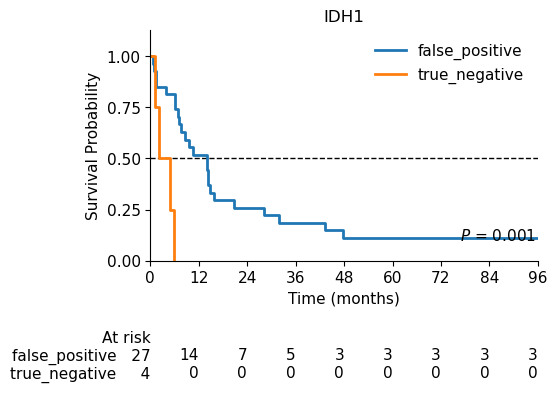

Variable: IDH1, Treatment group: aza_ven
Variable: IDH1, Treatment group: palliative
------------------------------------------------------------------------------------------------------------
Variable: IDH2, Treatment group: cyto
Variable: IDH2, Treatment group: aza
Variable: IDH2, Treatment group: aza_ven
Variable: IDH2, Treatment group: palliative
------------------------------------------------------------------------------------------------------------
Variable: t_11, Treatment group: cyto
Variable: t_11, Treatment group: aza
Variable: t_11, Treatment group: aza_ven
Variable: t_11, Treatment group: palliative
------------------------------------------------------------------------------------------------------------
Variable: TP53, Treatment group: cyto
Variable: TP53, Treatment group: aza
Variable: TP53, Treatment group: aza_ven
Variable: TP53, Treatment group: palliative
------------------------------------------------------------------------------------------------------------

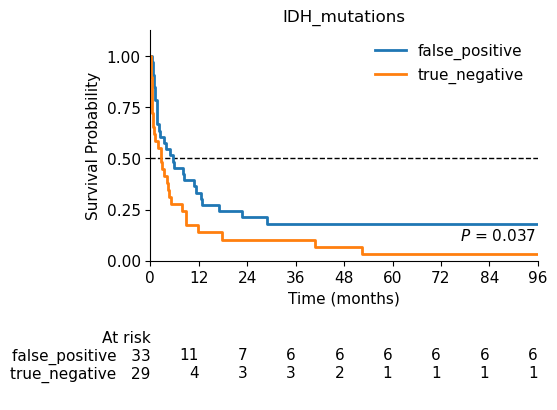

------------------------------------------------------------------------------------------------------------
Variable: RTK_RAS_mutations, Treatment group: cyto
Variable: RTK_RAS_mutations, Treatment group: aza
Variable: RTK_RAS_mutations, Treatment group: aza_ven
Variable: RTK_RAS_mutations, Treatment group: palliative
------------------------------------------------------------------------------------------------------------
Variable: monosomy_del_5, Treatment group: cyto


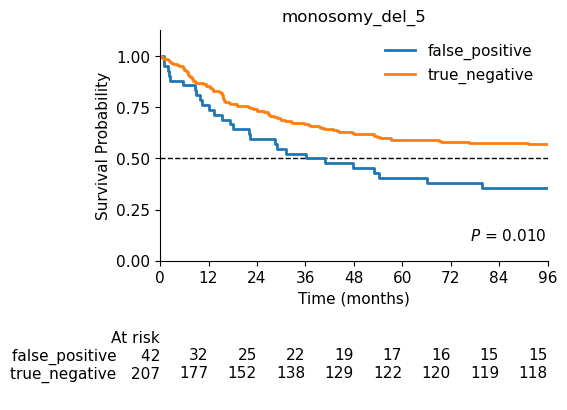

Variable: monosomy_del_5, Treatment group: aza
Variable: monosomy_del_5, Treatment group: aza_ven
Variable: monosomy_del_5, Treatment group: palliative
------------------------------------------------------------------------------------------------------------
Variable: WT1, Treatment group: cyto
Variable: WT1, Treatment group: aza
Variable: WT1, Treatment group: aza_ven
Variable: WT1, Treatment group: palliative
------------------------------------------------------------------------------------------------------------
Variable: PML-RARA, Treatment group: cyto
Variable: PML-RARA, Treatment group: aza
Variable: PML-RARA, Treatment group: aza_ven


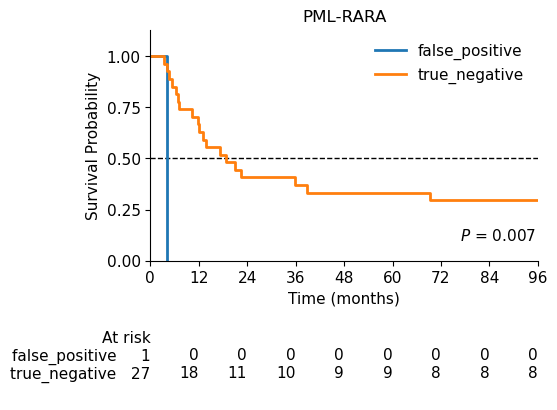

Variable: PML-RARA, Treatment group: palliative
------------------------------------------------------------------------------------------------------------
Variable: RUNX1, Treatment group: cyto
Variable: RUNX1, Treatment group: aza
Variable: RUNX1, Treatment group: aza_ven
Variable: RUNX1, Treatment group: palliative
------------------------------------------------------------------------------------------------------------
Variable: STAG2, Treatment group: cyto
Variable: STAG2, Treatment group: aza
Variable: STAG2, Treatment group: aza_ven
Variable: STAG2, Treatment group: palliative
------------------------------------------------------------------------------------------------------------
Variable: NRAS, Treatment group: cyto
Variable: NRAS, Treatment group: aza
Variable: NRAS, Treatment group: aza_ven
Variable: NRAS, Treatment group: palliative
------------------------------------------------------------------------------------------------------------
Variable: Transcription_muta

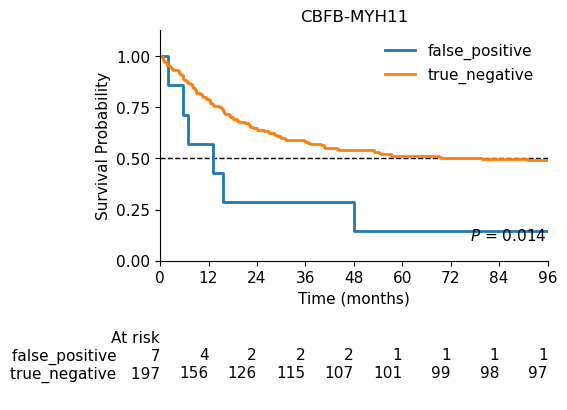

Variable: CBFB-MYH11, Treatment group: aza
Variable: CBFB-MYH11, Treatment group: aza_ven
Variable: CBFB-MYH11, Treatment group: palliative
------------------------------------------------------------------------------------------------------------
Variable: NPM1, Treatment group: cyto
Variable: NPM1, Treatment group: aza
Variable: NPM1, Treatment group: aza_ven
Variable: NPM1, Treatment group: palliative


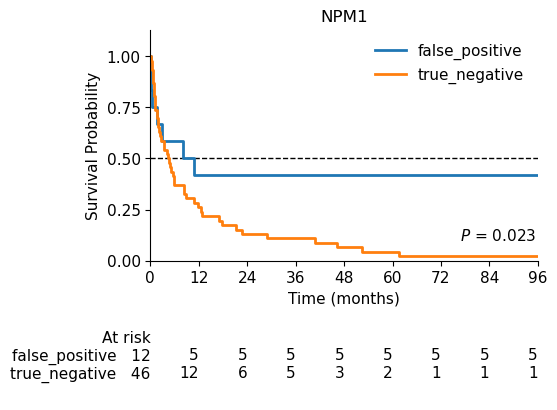

------------------------------------------------------------------------------------------------------------
Variable: BCOR_mutations, Treatment group: cyto
Variable: BCOR_mutations, Treatment group: aza


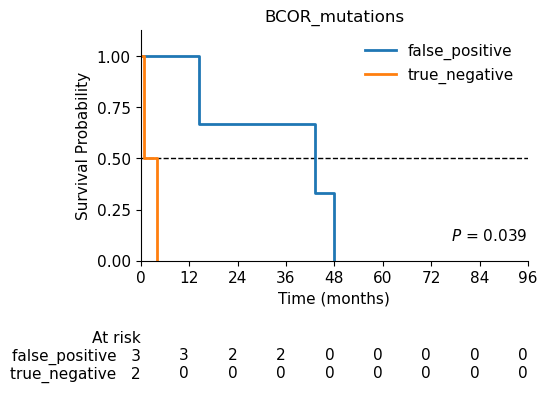

Variable: BCOR_mutations, Treatment group: aza_ven
Variable: BCOR_mutations, Treatment group: palliative
------------------------------------------------------------------------------------------------------------


In [41]:
plot_all_experiments(df_survival_pb, PREDICTION_RESULTS_DIR_PB, TREATMENT_GROUPS, PAIRS_TO_TEST)